<a href="https://colab.research.google.com/github/mtayyab03/AI-Google-Colab/blob/main/pca_lab_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab — Eigenvalues, Singular Values, and PCA

- **10 exercises worth 10 points each** (100 points total).
- Run cells in order. Fill in each `# YOUR CODE HERE` cell before running its check.
- Use NumPy for linear algebra and Matplotlib for plots. Build PCA from the SVD using your own functions. The data are generated in the setup cell. Keep the supplied `images/` folder next to this notebook to display the target figures.
- Match the data, geometry, and labels in each target figure. Colors and other styling may vary.

Rows are observations and columns are features. We use the **population covariance convention** ($1/n$). Write $X_c = X - \mathbf{1}\mu^\top$ for the column-centered data and set $A = X_c/\sqrt{n}$. With the thin SVD $A=U\operatorname{diag}(s)V^\top$, the rows of $V^\top$ are principal directions and $s^2$ gives their explained variances. We retain the original data scale when computing scores.

This lab uses synthetic data with features on comparable scales, so the only preprocessing step is mean centering.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})

rng = np.random.default_rng(17)
group = np.repeat(["Group A", "Group B", "Group C"], 60)
t = np.repeat([-3.1, 0.0, 3.1], 60) + rng.normal(0, 0.75, len(group))
u = rng.normal(0, 0.9, len(group))
angle = np.deg2rad(33)
rotation = np.array([[np.cos(angle), -np.sin(angle)],
                     [np.sin(angle), np.cos(angle)]])
X2 = np.column_stack([t, u]) @ rotation.T + [4, -2]
Q, _ = np.linalg.qr(np.array([
    [3., 1., 0., 1.], [2., -2., 1., 0.],
    [1., 2., 2., -1.], [2., 1., -2., 1.],
]))
latent = np.column_stack([
    t, u, rng.normal(0, 0.40, len(group)), rng.normal(0, 0.20, len(group))
])
X4 = latent @ Q.T + [4, -2, 1, 6]
# Group labels are for coloring plots only.

## Exercise 1 — Eigenpairs of a symmetric matrix [10 pts]

Implement `sorted_eigenpairs(B)` for a real symmetric square matrix of shape `(d, d)`.
Return `values, vectors` with shapes `(d,)` and `(d, d)`. Sort eigenvalues in descending
order and place the corresponding unit eigenvectors in **columns**. Use `np.linalg.eigh`.

A symmetric matrix can have negative eigenvalues. Verify $Bv_i=\lambda_i v_i$ in the check below.

In [2]:

def sorted_eigenpairs(B):
    # Calculate eigenvalues and eigenvectors
    values, vectors = np.linalg.eigh(B)

    # Sort eigenvalues in descending order
    indices = np.argsort(values)[::-1]

    values = values[indices]
    vectors = vectors[:, indices]

    return values, vectors


In [3]:
B = np.array([[1., 2.], [2., 1.]])
values, vectors = sorted_eigenpairs(B)
assert values.shape == (2,) and vectors.shape == (2, 2)
np.testing.assert_allclose(values, [3, -1])
np.testing.assert_allclose(B @ vectors, vectors * values, atol=1e-12)
np.testing.assert_allclose(vectors.T @ vectors, np.eye(2), atol=1e-12)
print("Exercise 1 checks passed.")

Exercise 1 checks passed.


## Exercise 2 — Thin SVD of a rectangular matrix [10 pts]

Implement `thin_svd(A)` using `np.linalg.svd`. For an `(m, d)` matrix,
let $r=\min(m,d)$ and return `U, s, Vt` with shapes `(m, r)`, `(r,)` and `(r, d)`.
The singular values should be nonnegative and in descending order.
Check reconstruction using $A=U\operatorname{diag}(s)V^\top$.

In [4]:

def thin_svd(A):
    # Calculate thin SVD
    U, s, Vt = np.linalg.svd(
        A,
        full_matrices=False
    )

    return U, s, Vt


In [5]:
A_demo = np.array([[3., 0.], [0., -2.], [0., 0.]])
for A in (A_demo, A_demo.T):
    U, s, Vt = thin_svd(A)
    m, d = A.shape
    r = min(m, d)
    assert U.shape == (m, r) and s.shape == (r,) and Vt.shape == (r, d)
    np.testing.assert_allclose(s, [3, 2])
    np.testing.assert_allclose(U @ np.diag(s) @ Vt, A, atol=1e-12)
print("Exercise 2 checks passed.")

Exercise 2 checks passed.


## Exercise 3 — Recover singular values from eigenvalues [10 pts]

Implement `singular_values_from_gram(A)` without calling an SVD.
Find the eigenvalues of $A^\top A$ using Exercise 1 and recover the singular values
from $\lambda_i(A^\top A)=s_i^2$. Clip tiny negative eigenvalues caused by roundoff to zero
before taking square roots. Return the largest $r=\min(m,d)$ values in descending order
so your output has the same shape as `s` in Exercise 2.

In [6]:

def singular_values_from_gram(A):
    # Calculate Gram matrix
    gram = A.T @ A

    # Calculate eigenvalues
    values, vectors = sorted_eigenpairs(gram)

    # Remove tiny negative values caused by rounding
    values = np.clip(values, 0, None)

    # Calculate number of singular values required
    r = min(A.shape)

    # Recover singular values
    s = np.sqrt(values[:r])

    return s


In [7]:
for A in (A_demo, np.array([[1., 2., 3.], [0., 1., 4.]]),
          np.array([[1., 2.], [2., 4.], [3., 6.]])):
    np.testing.assert_allclose(singular_values_from_gram(A), thin_svd(A)[1], atol=1e-7)
print("Exercise 3 checks passed.")

Exercise 3 checks passed.


## Exercise 4 — Center features [10 pts]

Implement `center_features(X)`. Return `Xc, mean` with shapes `(n, d)` and `(d,)`.
Compute one mean per feature and subtract it from every row. Leave the input array unchanged.

In [8]:

def center_features(X):
    # Calculate mean of each column
    mean = np.mean(X, axis=0)

    # Subtract the mean from each column
    Xc = X - mean

    return Xc, mean


In [9]:
example = np.array([[2, 10], [4, 16], [6, 10]])
before = example.copy()
Xc_example, mean_example = center_features(example)
assert Xc_example.shape == (3, 2) and mean_example.shape == (2,)
np.testing.assert_allclose(mean_example, [4, 12])
np.testing.assert_allclose(Xc_example.mean(axis=0), [0, 0], atol=1e-12)
np.testing.assert_allclose(Xc_example + mean_example, before)
np.testing.assert_array_equal(example, before)
print("Exercise 4 checks passed.")

Exercise 4 checks passed.


## Exercise 5 — Compute population covariance [10 pts]

Implement `population_covariance(X)` for raw observations. Reuse Exercise 4.
Return the `(d, d)` matrix $C=X_c^\top X_c/n$ using matrix multiplication.
The diagonal contains feature variances and the off-diagonal entries describe how pairs of features vary together.

In [10]:

def population_covariance(X):
    # Center the input data
    Xc, mean = center_features(X)

    # Number of observations
    n = X.shape[0]

    # Calculate population covariance
    C = (Xc.T @ Xc) / n

    return C


In [11]:
C = population_covariance(np.array([[1., 10.], [3., 14.]]))
assert C.shape == (2, 2)
np.testing.assert_allclose(C, [[1., 2.], [2., 4.]])
C4 = population_covariance(X4)
np.testing.assert_allclose(np.diag(C4), X4.var(axis=0))
print("Exercise 5 checks passed.")

Exercise 5 checks passed.


## Exercise 6 — Fit PCA through the scaled SVD [10 pts]

Implement `fit_pca(X)`. Center $X$, divide the centered matrix by $\sqrt{n}$,
and call `thin_svd` on that scaled matrix. Return `mean, components, variances`
with shapes `(d,)`, `(r, d)`, and `(r,)`, where $r=\min(n,d)$.
Each component is a **row**, and its variance is the corresponding squared singular value.
Use the full thin SVD here. You will select the first $k$ rows in later exercises.

For consistent plots, flip each row if its entry of largest absolute value is negative.
If there is a tie, use the first such entry. This selects a sign for each direction.

In [12]:

def fit_pca(X):
    # Center the data
    Xc, mean = center_features(X)

    # Number of observations
    n = X.shape[0]

    # Scale centered data
    A = Xc / np.sqrt(n)

    # Calculate thin SVD
    U, s, Vt = thin_svd(A)

    # Principal components
    components = Vt.copy()

    # Make signs consistent for plotting
    for i in range(len(components)):
        j = np.argmax(np.abs(components[i]))

        if components[i, j] < 0:
            components[i] *= -1

    # Explained variances
    variances = s ** 2

    return mean, components, variances


In [13]:
for X in (X2, X4, X4[:3]):
    mean, components, variances = fit_pca(X)
    n, d = X.shape
    r = min(n, d)
    assert mean.shape == (d,) and components.shape == (r, d) and variances.shape == (r,)
    np.testing.assert_allclose(mean, X.mean(axis=0))
    np.testing.assert_allclose(components @ components.T, np.eye(r), atol=1e-12)
    C = population_covariance(X)
    np.testing.assert_allclose(variances, sorted_eigenpairs(C)[0][:r], atol=1e-12)
    np.testing.assert_allclose(components.T @ np.diag(variances) @ components, C, atol=1e-12)
    assert np.all(components[np.arange(r), np.argmax(np.abs(components), axis=1)] >= 0)
print("Exercise 6 checks passed.")

Exercise 6 checks passed.


## Exercise 7 — Draw the principal directions [10 pts]

Use `fit_pca(X2)` and reproduce the target. Scatter the raw observations in feature space,
mark the mean, and draw a line segment for each principal direction. Use equal axis
aspect so the directions appear perpendicular.

For component $i$, the segment should run from $\mu-2\sqrt{\lambda_i}\,v_i$ to
$\mu+2\sqrt{\lambda_i}\,v_i$. Here $\lambda_i$ is the variance along $v_i$.
Label both segments and the axes.

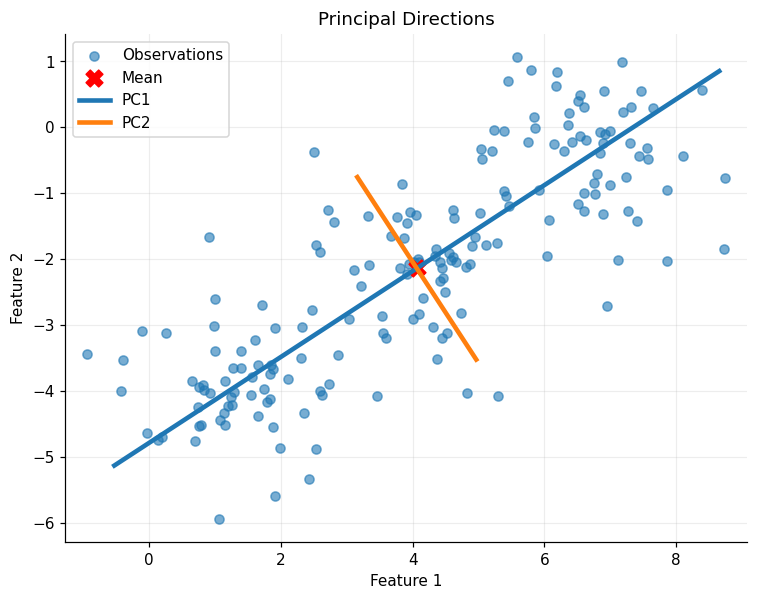

In [14]:

# Fit PCA
mean, components, variances = fit_pca(X2)

# Plot original observations
plt.figure(figsize=(8, 6))

plt.scatter(
    X2[:, 0],
    X2[:, 1],
    alpha=0.6,
    label="Observations"
)

# Mark the mean
plt.scatter(
    mean[0],
    mean[1],
    color="red",
    marker="X",
    s=120,
    label="Mean"
)

# Draw principal directions
for i in range(2):

    # Principal component
    v = components[i]

    # Explained variance
    lam = variances[i]

    # Calculate endpoints
    start = mean - 2 * np.sqrt(lam) * v
    end = mean + 2 * np.sqrt(lam) * v

    # Draw line
    plt.plot(
        [start[0], end[0]],
        [start[1], end[1]],
        linewidth=3,
        label=f"PC{i+1}"
    )

# Labels
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Principal Directions")

# Equal axis aspect
plt.axis("equal")

plt.legend()
plt.show()


**Target figure**

![Scatter with two perpendicular principal axes crossing at the mean](images/exercise07_target_directions.png)

## Exercise 8 — Project four features into two dimensions [10 pts]

Implement `pca_transform(X, mean, components, k)` with $1\le k\le r$.
Return scores of shape `(n, k)` by centering with the supplied **training** mean and
taking dot products with the first $k$ component rows. Use $X-\mathbf{1}\mu^\top$
at its original scale, without dividing by $\sqrt{n}$.

In the plotting cell, fit PCA on `X4`, compute its first two scores, and scatter PC1
against PC2 with PC1 on the horizontal axis. Color by `group` and add a legend.

In [15]:

def pca_transform(X, mean, components, k):
    # Select first k components
    selected = components[:k]

    # Center the data using training mean
    Xc = X - mean

    # Project data into lower dimensions
    Z = Xc @ selected.T

    return Z


In [16]:
mean4, components4, variances4 = fit_pca(X4)
Z4 = pca_transform(X4, mean4, components4, 2)
assert Z4.shape == (len(X4), 2)
np.testing.assert_allclose(Z4.mean(axis=0), [0, 0], atol=1e-12)
np.testing.assert_allclose(Z4.T @ Z4 / len(X4), np.diag(variances4[:2]), atol=1e-12)
# A single new observation still uses the training mean.
new = mean4 + 3 * components4[0]
np.testing.assert_allclose(pca_transform(new[None, :], mean4, components4, 2),
                           [[3, 0]], atol=1e-12)
print("Exercise 8 checks passed.")

Exercise 8 checks passed.


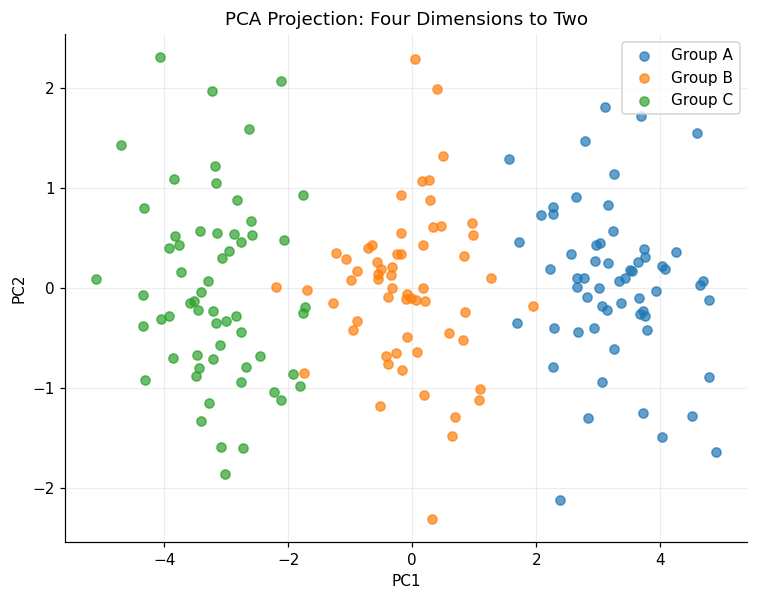

In [17]:

# Fit PCA on four-feature dataset
mean4, components4, variances4 = fit_pca(X4)

# Transform data into two dimensions
Z4 = pca_transform(
    X4,
    mean4,
    components4,
    2
)

# Plot projected data
plt.figure(figsize=(8, 6))

# Plot each group separately
for g in np.unique(group):

    mask = group == g

    plt.scatter(
        Z4[mask, 0],
        Z4[mask, 1],
        label=g,
        alpha=0.7
    )

# Labels
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection: Four Dimensions to Two")

plt.legend()
plt.show()


**Target figure**

![Two-dimensional score scatter colored by group](images/exercise08_target_projection.png)

## Exercise 9 — Reconstruct observations from one component [10 pts]

Implement `pca_inverse_transform(Z, mean, components)`. If `Z` has $k$ columns,
return reconstructed rows of shape `(n, d)` using the first $k$ component rows and
adding back the training mean.

In the plotting cell, project `X2` onto PC1 and reconstruct it in the original feature space.
Overlay the original and reconstructed points with equal axis aspect. Connect every
sixth original point (rows 0, 6, 12, …) to its reconstruction. Label axes and point types.

In [18]:

def pca_inverse_transform(Z, mean, components):
    # Number of components in Z
    k = Z.shape[1]

    # Select first k components
    selected = components[:k]

    # Reconstruct original observations
    X_hat = Z @ selected + mean

    return X_hat


In [19]:
mean2, components2, variances2 = fit_pca(X2)
Z1 = pca_transform(X2, mean2, components2, 1)
X_hat = pca_inverse_transform(Z1, mean2, components2)
assert X_hat.shape == X2.shape
np.testing.assert_allclose((X2 - X_hat) @ components2[0], 0, atol=1e-12)
np.testing.assert_allclose(np.mean(np.sum((X2 - X_hat)**2, axis=1)), variances2[1])
Z2 = pca_transform(X2, mean2, components2, 2)
np.testing.assert_allclose(pca_inverse_transform(Z2, mean2, components2), X2, atol=1e-12)
print("Exercise 9 checks passed.")

Exercise 9 checks passed.


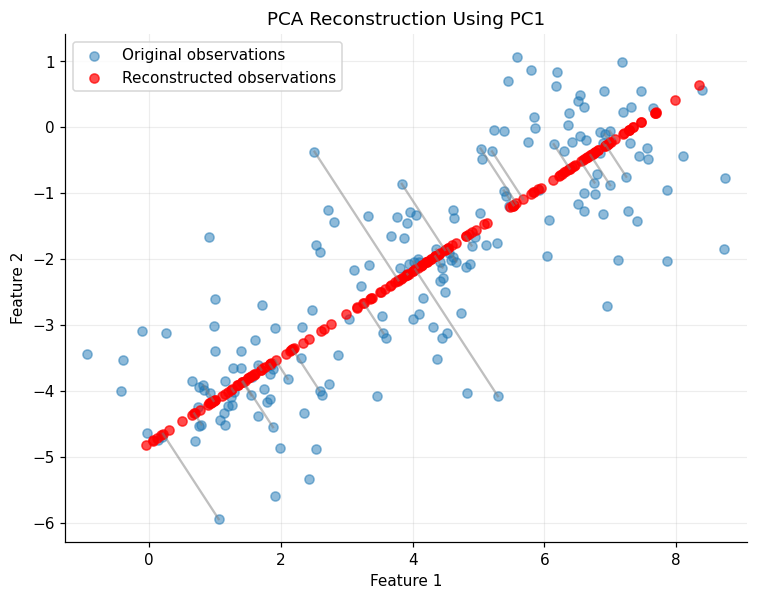

In [20]:

# Fit PCA on X2
mean2, components2, variances2 = fit_pca(X2)

# Project observations onto PC1
Z1 = pca_transform(
    X2,
    mean2,
    components2,
    1
)

# Reconstruct observations
X_hat = pca_inverse_transform(
    Z1,
    mean2,
    components2
)

# Create plot
plt.figure(figsize=(8, 6))

# Original observations
plt.scatter(
    X2[:, 0],
    X2[:, 1],
    alpha=0.5,
    label="Original observations"
)

# Reconstructed observations
plt.scatter(
    X_hat[:, 0],
    X_hat[:, 1],
    color="red",
    alpha=0.7,
    label="Reconstructed observations"
)

# Connect every sixth original point
for i in range(0, len(X2), 6):

    plt.plot(
        [X2[i, 0], X_hat[i, 0]],
        [X2[i, 1], X_hat[i, 1]],
        color="gray",
        alpha=0.5
    )

# Labels
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("PCA Reconstruction Using PC1")

plt.axis("equal")
plt.legend()
plt.show()


**Target figure**

![Original observations and their perpendicular projections onto PC1](images/exercise09_target_reconstruction.png)

## Exercise 10 — Choose a dimension by explained variance [10 pts]

Implement `variance_summary(variances, target=0.95)`. Assume the variances are descending
and have positive sum, and $0<\text{target}\le1$. Return `ratios, cumulative, k`.
The ratios divide each variance by the total, the cumulative array sums those ratios in
component order, and $k$ is the smallest number of components whose cumulative
ratio reaches the target. Account for floating-point roundoff when the target is 1.

For `X4`, plot individual explained variance ratios as bars and cumulative ratios as a
line on the same axes. Number components starting at 1 and mark the 95% level.

In the last Markdown cell, state the smallest $k$ that reaches 95%, how much variance
those components explain, and how this relates to the two-dimensional plot in Exercise 8.

In [21]:

def variance_summary(variances, target=0.95):
    # Calculate total variance
    total = np.sum(variances)

    # Calculate individual explained variance ratios
    ratios = variances / total

    # Calculate cumulative explained variance
    cumulative = np.cumsum(ratios)

    # Find the smallest k reaching target
    reached = np.where(
        cumulative >= target - 1e-12
    )[0]

    k = int(reached[0] + 1) if len(reached) else len(variances)

    return ratios, cumulative, k


In [22]:
ratios, cumulative, k = variance_summary(np.array([5., 2., 1.]), target=0.875)
np.testing.assert_allclose(ratios, [0.625, 0.25, 0.125])
np.testing.assert_allclose(cumulative, [0.625, 0.875, 1.0])
assert k == 2
assert variance_summary(np.ones(7), target=1.0)[2] == 7
ratios4, cumulative4, k4 = variance_summary(variances4)
assert cumulative4[k4 - 1] >= 0.95 - 1e-12
assert k4 == 1 or cumulative4[k4 - 2] < 0.95
print("Exercise 10 checks passed.")

Exercise 10 checks passed.


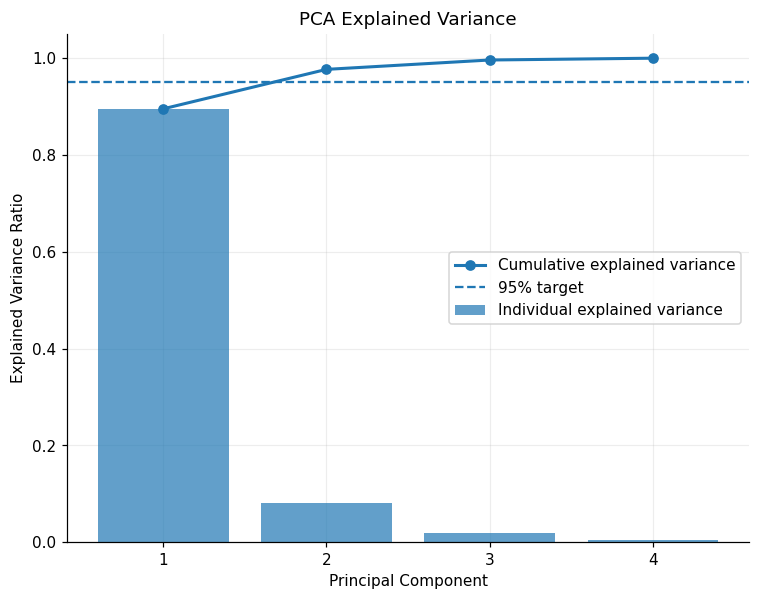

Individual ratios: [0.89542629 0.08147571 0.01935062 0.00374739]
Cumulative ratios: [0.89542629 0.97690199 0.99625261 1.        ]
Number of components required: 2
Variance explained: 97.69019938342068 %


In [23]:

# Fit PCA on X4
mean4, components4, variances4 = fit_pca(X4)

# Calculate explained variance
ratios4, cumulative4, k4 = variance_summary(
    variances4,
    target=0.95
)

# Component numbers
components = np.arange(1, len(ratios4) + 1)

# Create plot
plt.figure(figsize=(8, 6))

# Individual explained variance
plt.bar(
    components,
    ratios4,
    alpha=0.7,
    label="Individual explained variance"
)

# Cumulative explained variance
plt.plot(
    components,
    cumulative4,
    marker="o",
    linewidth=2,
    label="Cumulative explained variance"
)

# Mark 95% target
plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% target"
)

# Labels
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")

plt.xticks(components)
plt.legend()
plt.show()

# Display results
print("Individual ratios:", ratios4)
print("Cumulative ratios:", cumulative4)
print("Number of components required:", k4)
print("Variance explained:", cumulative4[k4-1] * 100, "%")


**Target figure**

![Individual bars and cumulative line with a horizontal 95 percent target](images/exercise10_target_variance.png)

**Your interpretation**

<!-- Write your answer here. -->